In [1]:
import matplotlib.pyplot as plt
import numpy as np
import itertools
import torch
import torch.nn.functional as F
from torch import nn, optim
from torch.nn import init
from torchinfo import summary
import torchbnn as bnn
import math

from mmbo.examples.testfunc import li2_energy, be2_energy, nice_periodic
from mmbo.nn import BayesianLoss, GaussianLoss, NetworkBayesianLoss, NetworkGaussianLoss
from mmbo.nn import MeanSD
from mmbo.nn import TIBNN

In [2]:
def _train_data(func, modes, xmin, xmax, ntrainpergroup, seed, full):
    rng = np.random.default_rng(seed)
    ntrain = ntrainpergroup * (2 ** len(modes) - 1)
    # Training Data
    X_train = np.linspace(xmin, xmax, num=ntrain)
    rng.shuffle(X_train)
    Y_train = np.empty((ntrain, len(modes)))
    Y_train.fill(np.nan)
    combinations = list(itertools.chain.from_iterable([itertools.combinations(range(len(modes)), r) for r in range(1,len(modes)+1)])) * ntrainpergroup
    for r in range(ntrain):
        for c in combinations[r]:
            Y_train[r,c] = func(X_train[r], modes[c])
    Y_train_full = np.zeros((ntrain, len(modes)))
    for i,m in enumerate(modes):
        Y_train_full[:,i] = func(X_train, m)
    # Package and return
    X_train_pt = torch.Tensor(np.float32(X_train.reshape((ntrain,1))))
    Y_train_pt = torch.Tensor(np.float32(Y_train))
    Y_train_full_pt = torch.Tensor(np.float32(Y_train_full))
    if full:
        return X_train_pt, Y_train_pt, Y_train_full_pt
    else:
        return X_train_pt, Y_train_pt

def _molecule_train_data(func, xmin, xmax, ntrainpergroup, seed, full):
    modes = func.modes
    return _train_data(func, modes, xmin, xmax, ntrainpergroup, seed, full)

def li2_train_data(ntrainpergroup, seed=None, full=False):
    return _molecule_train_data(li2_energy, 0.5, 11.0, ntrainpergroup, seed, full)

def be2_train_data(ntrainpergroup, seed=None, full=False):
    return _molecule_train_data(be2_energy, 0.5, 5.0, ntrainpergroup, seed, full)

def nice_periodic_train_data(ntrainpergroup, nummodes=5, seed=None, full=False):
    return _train_data(nice_periodic, list(range(nummodes)), -np.pi, np.pi, ntrainpergroup, seed, full)



Text(0.5, 1.0, 'Training Data')

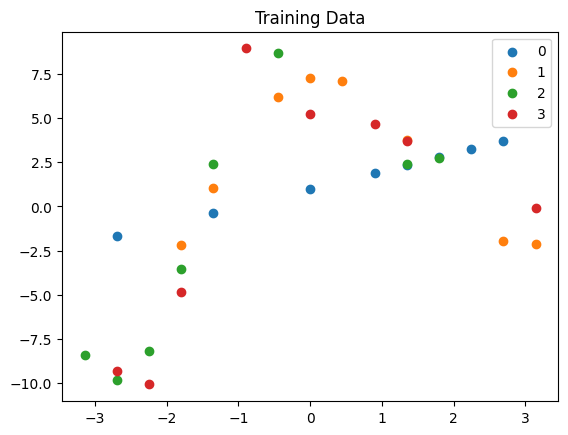

In [36]:
X_train_pt, Y_train_pt, Y_train_full_pt = nice_periodic_train_data(1, 4, 1234, full=True)

for i,m in enumerate(range(Y_train_pt.shape[1])):
    plt.scatter(X_train_pt.detach(), Y_train_pt.detach()[:,i], label=m)
plt.legend(loc="upper right")
plt.title("Training Data")

# Validation Data

#X_val = np.arange(X_train_pt.detach().min(), X_train_pt.detach().max(), 0.01)
#nval = len(X_val)

#Y_val = np.zeros((nval, len(li2_modes)))
#for i,m in enumerate(li2_modes):
#    Y_val[:,i] = li2_energy(X_val, m)

#X_val_pt = torch.Tensor(np.float32(X_val.reshape((nval,1))))
#Y_val_pt = torch.Tensor(np.float32(Y_val))

# Select specific modality
#mode = 1
#newshape = (Y_train_pt.shape[0], 1)
#Y_train_pt = Y_train_pt[:,mode].reshape(newshape)
#Y_train_full_pt = Y_train_full_pt[:,mode].reshape(newshape)


In [37]:
# Now we can train the model
def train_bayesian_model(model, num_epochs, learning_rate, X_train, Y_train, sigma=None):
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    lossfunc = BayesianLoss()
    if sigma is None:
        optimizer.add_param_group({"params": lossfunc.parameters()})
    else:
        lossfunc.setsigma_(sigma)

    total_loss = 0.0
    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad()
        Y_train_est_mean = model(X_train)
        loss = lossfunc(model, Y_train_est_mean, Y_train)
        total_loss += loss.item()
        if (epoch + 1) % (num_epochs // 10) == 0:
            avg_loss = total_loss / (num_epochs // 10)
            print("Epoch {}: Training Loss = {}, Sigma={}".format(epoch, avg_loss, np.exp(lossfunc.logsigma.item())))
            total_loss = 0.0
        loss.backward()
        optimizer.step()
        model.eval()

In [38]:
width = 100

model = TIBNN.from_data(X_train_pt, Y_train_pt, width=width, depth=1, sigma_prior_median=0.01, sigma_prior_scale=2)

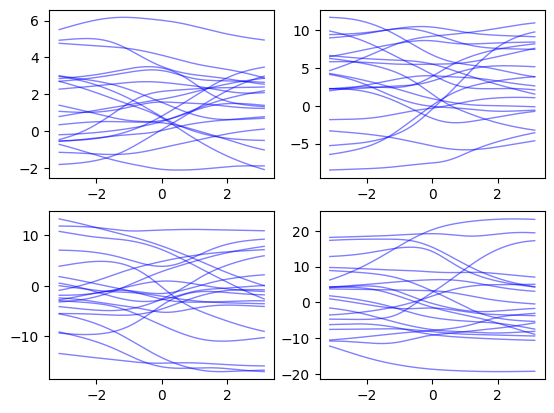

In [39]:
# Plot realizations of prior
model.initialize_(prior=True)

func = nice_periodic
modes = [0,1,2,3]
#modes = [0]

X_plot = np.arange(-np.pi, np.pi, .01)
#X_plot = X_val
nplot = len(X_plot)
X_plot_pt = torch.Tensor(np.float32(X_plot.reshape((nplot, 1))))
num_est=20


nummodes = len(modes)
figrows = np.ceil(np.sqrt(nummodes)).astype(int)
figcols = np.ceil(nummodes / figrows).astype(int)

fig, axs = plt.subplots(figrows, figcols)
if not isinstance(axs, np.ndarray):
    axs = np.array(axs)
axs = axs.flatten()

for i in range(num_est):
    Y_plot_mean_pt = model(X_plot_pt)
    #Y_plot_mean_pt, Y_plot_sd_pt = model(X_plot_pt)
    Y_plot_pt = Y_plot_mean_pt
    #Y_plot_pt_high = Y_plot_mean_pt + 2 * Y_plot_sd_pt
    #Y_plot_pt_low = Y_plot_mean_pt - 2 * Y_plot_sd_pt
    for m in range(nummodes):
        axs[m].plot(X_plot, Y_plot_pt[:,m].detach(), color="blue", alpha=0.5, linewidth=1, zorder=5)
        #axs[m].plot(X_plot, Y_plot_pt_high[:,m].detach(), color="green", alpha=0.25, linewidth=1, zorder=5)
        #axs[m].plot(X_plot, Y_plot_pt_low[:,m].detach(), color="green", alpha=0.25, linewidth=1, zorder=5)

model.initialize_(prior=False)

In [40]:

learning_rate = 1e-3
num_epochs = 100000

train_bayesian_model(model, num_epochs, learning_rate, X_train_pt, Y_train_pt, sigma=0.01)

Epoch 9999: Training Loss = 875048.8025835938, Sigma=0.009999999360491285
Epoch 19999: Training Loss = 68473.67550273438, Sigma=0.009999999360491285
Epoch 29999: Training Loss = 14338.78464921875, Sigma=0.009999999360491285
Epoch 39999: Training Loss = 4566.878838525391, Sigma=0.009999999360491285
Epoch 49999: Training Loss = 3276.7935104003905, Sigma=0.009999999360491285
Epoch 59999: Training Loss = 2859.458659448242, Sigma=0.009999999360491285
Epoch 69999: Training Loss = 2683.9628209228517, Sigma=0.009999999360491285
Epoch 79999: Training Loss = 2574.7356580078126, Sigma=0.009999999360491285
Epoch 89999: Training Loss = 2503.3215060546877, Sigma=0.009999999360491285
Epoch 99999: Training Loss = 2455.621207055664, Sigma=0.009999999360491285


In [45]:
initial_factor = 5.0
decay_factor = 2.0
num_splits = 9

for lrfactor in decay_factor ** np.array(range(0, -num_splits, -1)):
    print("Learning rate: {}".format(initial_factor * learning_rate * lrfactor))
    train_bayesian_model(model, num_epochs // num_splits, 
                         initial_factor * learning_rate * lrfactor, 
                         X_train_pt, Y_train_pt, sigma=0.01)

Learning rate: 0.005
Epoch 1110: Training Loss = 3626.1700304307774, Sigma=0.009999999360491285
Epoch 2221: Training Loss = 3116.939700561853, Sigma=0.009999999360491285
Epoch 3332: Training Loss = 3023.273367180468, Sigma=0.009999999360491285
Epoch 4443: Training Loss = 3074.9095811680777, Sigma=0.009999999360491285
Epoch 5554: Training Loss = 3100.234581783374, Sigma=0.009999999360491285
Epoch 6665: Training Loss = 2981.6174362553443, Sigma=0.009999999360491285
Epoch 7776: Training Loss = 2993.7373451212306, Sigma=0.009999999360491285
Epoch 8887: Training Loss = 3025.6009147911864, Sigma=0.009999999360491285
Epoch 9998: Training Loss = 3031.067025721127, Sigma=0.009999999360491285
Epoch 11109: Training Loss = 2964.4182645315313, Sigma=0.009999999360491285
Learning rate: 0.0025
Epoch 1110: Training Loss = 2442.5902803903437, Sigma=0.009999999360491285
Epoch 2221: Training Loss = 2475.127224624318, Sigma=0.009999999360491285
Epoch 3332: Training Loss = 2406.834329599952, Sigma=0.009999

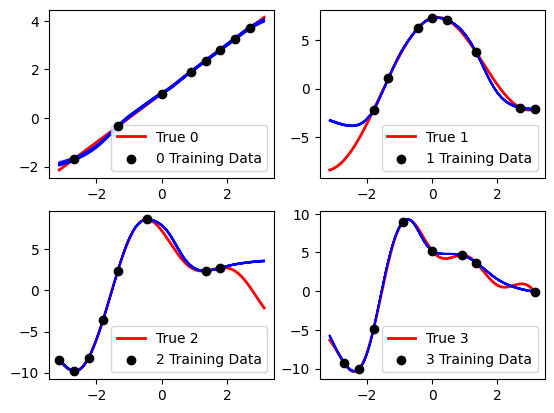

In [46]:
# Plot the estimated functions
X_train = X_train_pt.detach()
Y_train = Y_train_pt.detach()

func = nice_periodic
modes = [0,1,2,3]
#modes = [0]

X_plot = np.arange(-np.pi, np.pi, .01)
#X_plot = X_val
nplot = len(X_plot)
X_plot_pt = torch.Tensor(np.float32(X_plot.reshape((nplot, 1))))
num_est=50


nummodes = len(modes)
figrows = np.ceil(np.sqrt(nummodes)).astype(int)
figcols = np.ceil(nummodes / figrows).astype(int)

fig, axs = plt.subplots(figrows, figcols)
if not isinstance(axs, np.ndarray):
    axs = np.array(axs)
axs = axs.flatten()

for i in range(num_est):
    #Y_plot_mean_pt, Y_plot_sd_pt = model(X_plot_pt)
    Y_plot_mean_pt = model(X_plot_pt)
    Y_plot_pt = Y_plot_mean_pt
    #Y_plot_pt_high = Y_plot_mean_pt + 2 * Y_plot_sd_pt
    #Y_plot_pt_low = Y_plot_mean_pt - 2 * Y_plot_sd_pt
    for m in range(nummodes):
        axs[m].plot(X_plot, Y_plot_pt[:,m].detach(), color="blue", alpha=0.5, linewidth=1, zorder=5)
        #axs[m].plot(X_plot, Y_plot_pt_high[:,m].detach(), color="green", alpha=0.25, linewidth=1, zorder=5)
        #axs[m].plot(X_plot, Y_plot_pt_low[:,m].detach(), color="green", alpha=0.25, linewidth=1, zorder=5)

for m in range(nummodes):
    axs[m].plot(X_plot, func(X_plot, modes[m]), label="True "+str(modes[m]), color="red", linewidth=2, zorder=0)
    axs[m].scatter(X_train, Y_train[:,m], label=str(modes[m])+" Training Data", color="black", zorder=10)
    axs[m].legend(loc="lower right")
